# Training panel exploration

This notebook only looks at `training_panel_2021.csv`. No model.

Each row is one **New Jersey workplace** on one day of 2021.

| Column | Meaning |
|---|---|
| `zipcode` | Workplace ZCTA |
| `date` | Day |
| `daily_cases` | Cases reported in that workplace ZCTA |
| `velocity` | Today's cases minus yesterday's |
| `acceleration` | Today's velocity minus yesterday's |
| `jerk` | Today's acceleration minus yesterday's |
| `pressure` | Commute-weighted cases flowing **in** from other NJ ZCTAs and NYC |
| `weight_coverage` | Share of inbound commute weights that had a case count (1 in this file) |

Run from the project root, or from this folder. The loader checks both.


## 1. Load

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

path = Path("training_panel_2021.csv")
if not path.exists():
    path = Path("Dhruvesh/training/training_panel_2021.csv")

panel = pd.read_csv(path, dtype={"zipcode": str}, parse_dates=["date"])
panel["zipcode"] = panel["zipcode"].str.zfill(5)
panel = panel.sort_values(["zipcode", "date"]).reset_index(drop=True)

print(path.resolve())
print(f"{panel.shape[0]:,} rows  x  {panel.shape[1]} columns")
print(f"{panel.zipcode.nunique()} workplaces   {panel.date.min().date()} to {panel.date.max().date()}")
panel.head()


/Users/dhruvesh/Desktop/Fall 2026/Analytics/Jupyter/Dhruvesh/training/training_panel_2021.csv
215,350 rows  x  8 columns
590 workplaces   2021-01-01 to 2021-12-31


,zipcode,date,daily_cases,velocity,acceleration,jerk,pressure,weight_coverage
0,07001,2021-01-01,10,NaN,NaN,NaN,27.789434,1.0
1,07001,2021-01-02,17,7.0,NaN,NaN,22.523684,1.0
2,07001,2021-01-03,5,-12.0,-19.0,NaN,21.082964,1.0
3,07001,2021-01-04,29,24.0,36.0,55.0,27.015162,1.0
4,07001,2021-01-05,18,-11.0,-35.0,-71.0,26.767210,1.0


## 2. Summary stats

`describe` is the quick picture: typical value, spread, smallest, largest.

`daily_cases` and `pressure` stay at or above zero. `velocity`, `acceleration`, and `jerk` can be negative, because they are changes: a negative velocity means cases fell from yesterday.


In [2]:
panel.describe().round(2)


,date,daily_cases,velocity,acceleration,jerk,pressure,weight_coverage
count,215350,215350.00,214760.00,214170.00,213580.00,215350.00,215350.0
mean,2021-07-02 00:00:00,3.52,0.01,0.00,0.00,6.28,1.0
min,2021-01-01 00:00:00,0.00,-513.00,-1043.00,-1561.00,0.00,1.0
25%,2021-04-02 00:00:00,0.00,-1.00,-2.00,-3.00,1.07,1.0
50%,2021-07-02 00:00:00,1.00,0.00,0.00,0.00,2.34,1.0
75%,2021-10-01 00:00:00,3.00,1.00,2.00,3.00,8.49,1.0
max,2021-12-31 00:00:00,646.00,530.00,617.00,1660.00,79.25,1.0
std,NaN,8.48,6.47,11.06,20.04,7.84,0.0


In [3]:
print("Blank cells (expected on the first days of each workplace):")
print(panel.isna().sum())
print()
print("First date per workplace:", panel.groupby("zipcode").date.min().nunique(), "unique value")
print("Days per workplace:", panel.groupby("zipcode").size().unique().tolist())


Blank cells (expected on the first days of each workplace):
zipcode               0
date                  0
daily_cases           0
velocity            590
acceleration       1180
jerk               1770
pressure              0
weight_coverage       0
dtype: int64

First date per workplace: 1 unique value
Days per workplace: [365]


## 3. One workplace, one week

Read across a row. `daily_cases` is the level. `velocity` is how that level moved since yesterday.


In [4]:
example_zip = panel.zipcode.iloc[0]
week = panel.loc[
    panel.zipcode.eq(example_zip) & panel.date.between("2021-01-01", "2021-01-10")
]
print("Workplace", example_zip)
week.round(2)


Workplace 07001


/var/folders/9g/dc1_4w692z950j8_8mfyy4rc0000gn/T/ipykernel_23348/3477990246.py:6: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  week.round(2)


,zipcode,date,daily_cases,velocity,acceleration,jerk,pressure,weight_coverage
0,07001,2021-01-01,10,NaN,NaN,NaN,27.79,1.0
1,07001,2021-01-02,17,7.0,NaN,NaN,22.52,1.0
2,07001,2021-01-03,5,-12.0,-19.0,NaN,21.08,1.0
3,07001,2021-01-04,29,24.0,36.0,55.0,27.02,1.0
4,07001,2021-01-05,18,-11.0,-35.0,-71.0,26.77,1.0
5,07001,2021-01-06,10,-8.0,3.0,38.0,25.82,1.0
6,07001,2021-01-07,14,4.0,12.0,9.0,29.58,1.0
7,07001,2021-01-08,23,9.0,5.0,-7.0,25.15,1.0
8,07001,2021-01-09,6,-17.0,-26.0,-31.0,19.73,1.0
9,07001,2021-01-10,7,1.0,18.0,44.0,22.66,1.0


## 4. Six workplaces across the year

The six ZIP codes are spread from quieter to busier, by total 2021 cases. The line chart is the outbreak shape. The histogram is how often a day had few cases versus many.


In [5]:
totals = panel.groupby("zipcode").daily_cases.sum().sort_values()
picks = totals.iloc[[0, len(totals) // 5, 2 * len(totals) // 5, 3 * len(totals) // 5, 4 * len(totals) // 5, -1]]
print("Six workplaces, quietest to busiest (total cases in 2021):")
print(picks.round(0).astype(int).to_string())

sample = panel.loc[panel.zipcode.isin(picks.index)].copy()


Six workplaces, quietest to busiest (total cases in 2021):
zipcode
08073        0
08804      279
08501      633
07075     1098
07901     2048
08701    11198


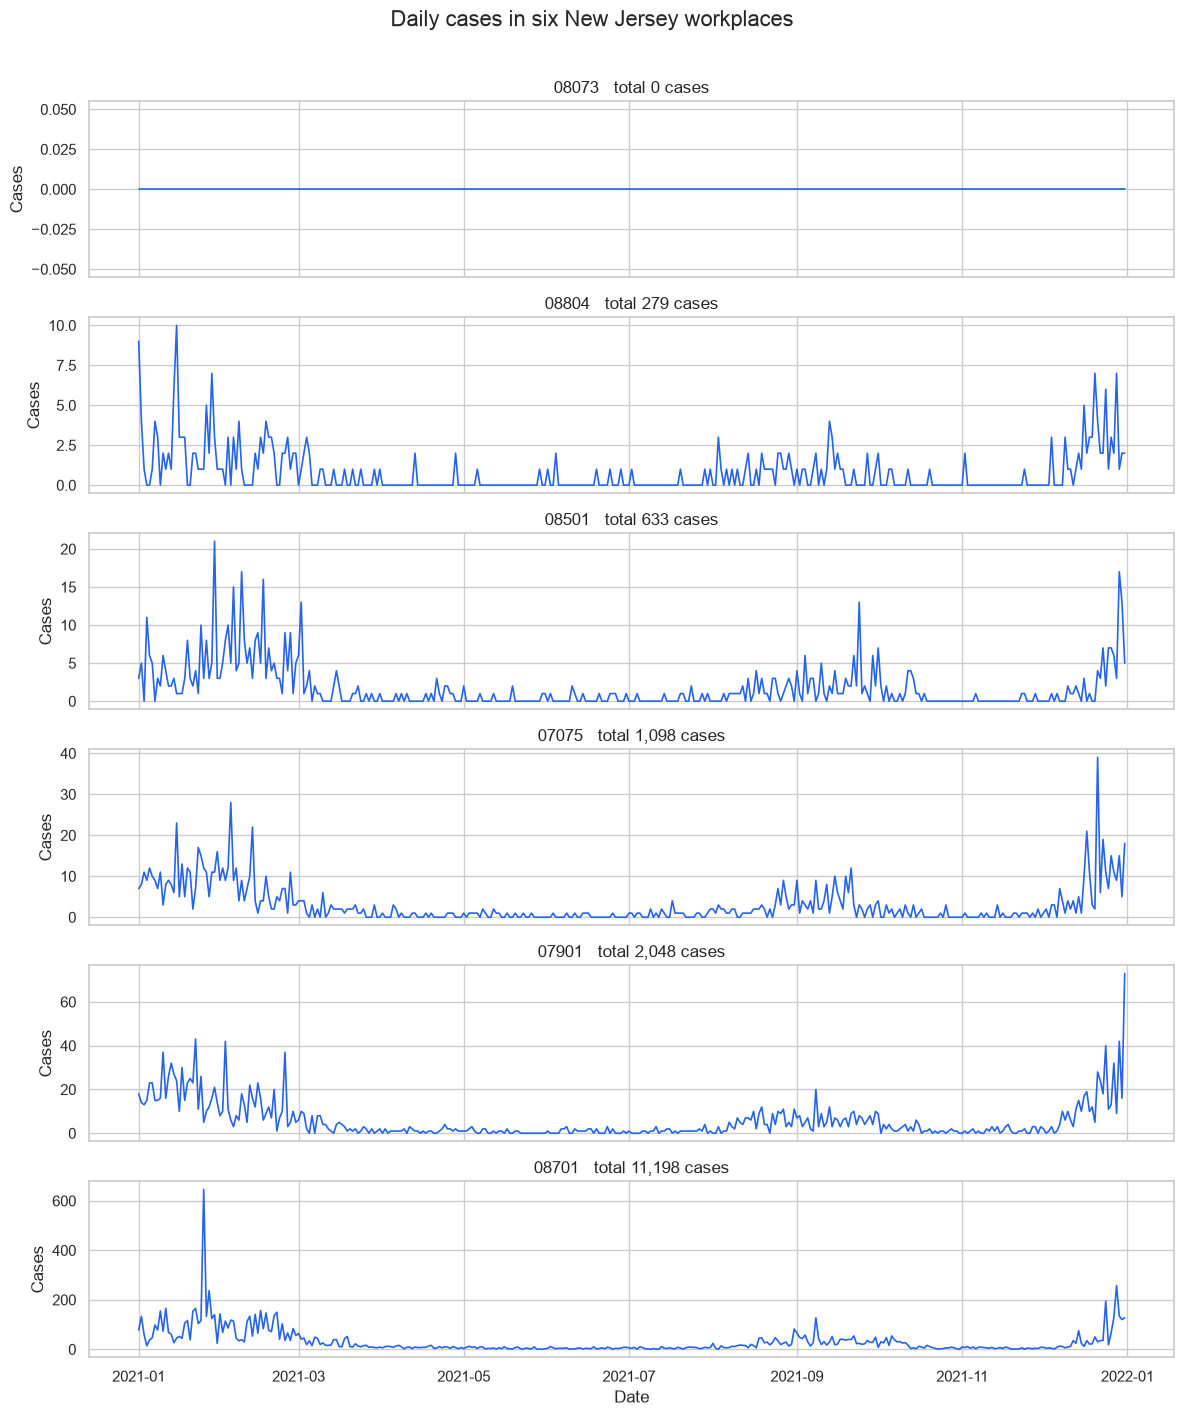

In [6]:
fig, axes = plt.subplots(6, 1, figsize=(12, 14), sharex=True)
for ax, zipcode in zip(axes, picks.index):
    one = sample.loc[sample.zipcode.eq(zipcode)]
    ax.plot(one.date, one.daily_cases, color="#2563EB", linewidth=1.2)
    ax.set_ylabel("Cases")
    ax.set_title(f"{zipcode}   total {int(picks.loc[zipcode]):,} cases")
axes[-1].set_xlabel("Date")
fig.suptitle("Daily cases in six New Jersey workplaces", y=1.01, fontsize=16)
fig.tight_layout()
plt.show()


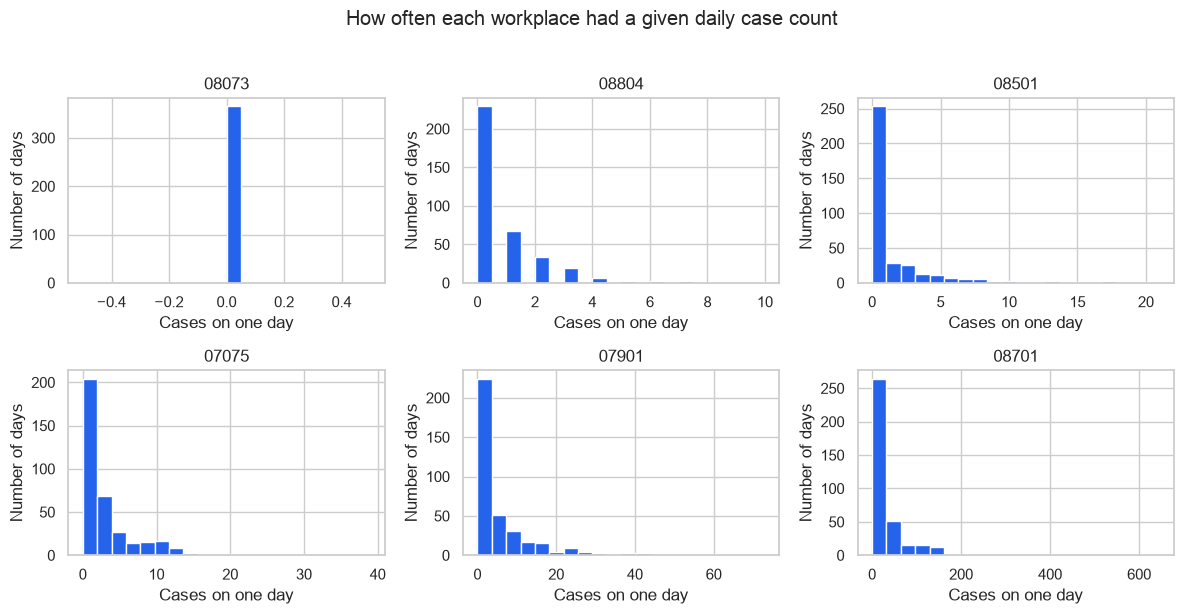

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, zipcode in zip(axes.ravel(), picks.index):
    one = sample.loc[sample.zipcode.eq(zipcode), "daily_cases"]
    ax.hist(one, bins=20, color="#2563EB", edgecolor="white")
    ax.set_title(zipcode)
    ax.set_xlabel("Cases on one day")
    ax.set_ylabel("Number of days")
fig.suptitle("How often each workplace had a given daily case count", y=1.02)
fig.tight_layout()
plt.show()


## 5. Local cases next to commute pressure

`daily_cases` is sickness **in** the workplace ZIP code. `pressure` is sickness **commuting in**, weighted by the 2021 job shares. They can rise together without being the same number.


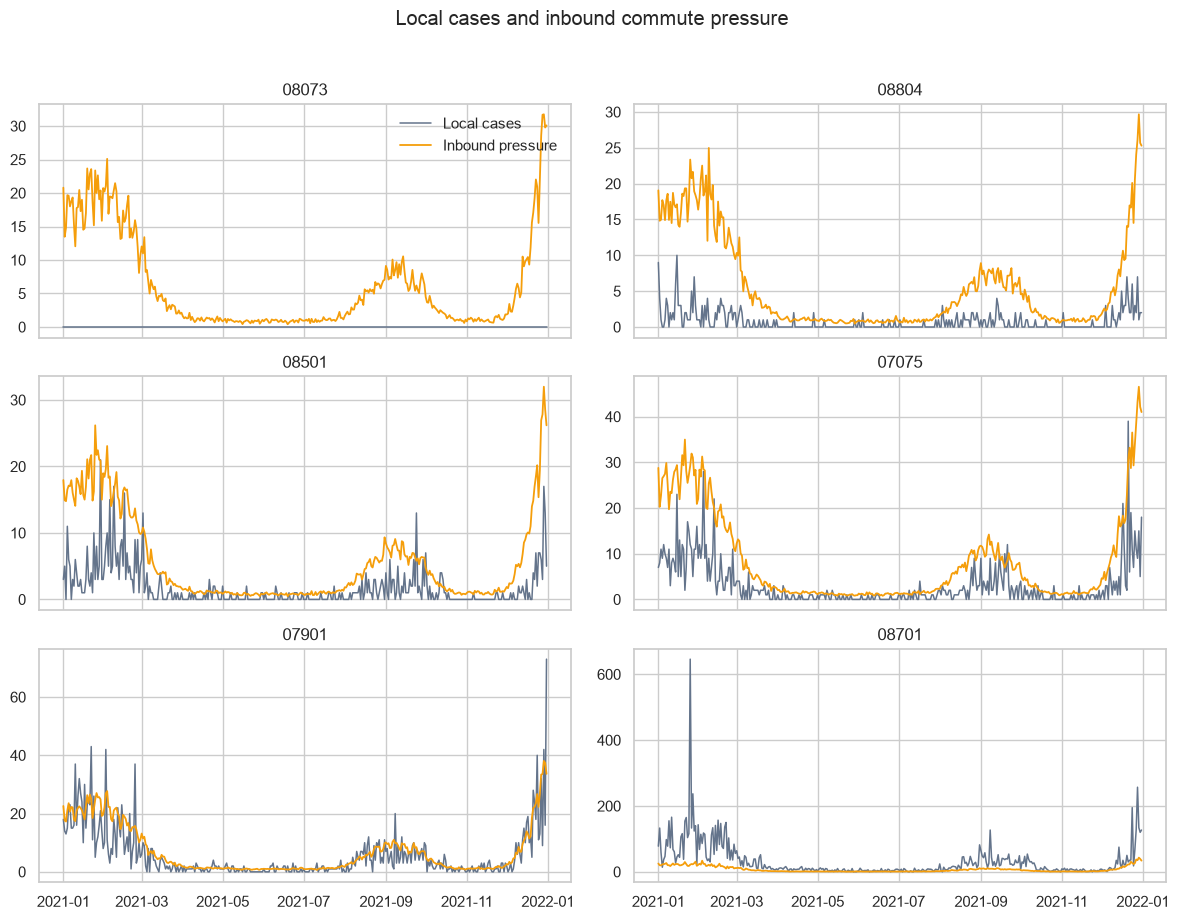

In [8]:
fig, axes = plt.subplots(3, 2, figsize=(12, 9), sharex=True)
for ax, zipcode in zip(axes.ravel(), picks.index):
    one = sample.loc[sample.zipcode.eq(zipcode)]
    ax.plot(one.date, one.daily_cases, color="#64748B", linewidth=1.1, label="Local cases")
    ax.plot(one.date, one.pressure, color="#F59E0B", linewidth=1.3, label="Inbound pressure")
    ax.set_title(zipcode)
axes.ravel()[0].legend(frameon=False, loc="upper right")
fig.suptitle("Local cases and inbound commute pressure", y=1.02)
fig.tight_layout()
plt.show()


## 6. All workplaces together

The first histogram is every workplace-day. Most days are small. A few days are large, which is the January and December waves.

The second chart adds cases across all 590 workplaces, so the shared 2021 shape is easy to see.


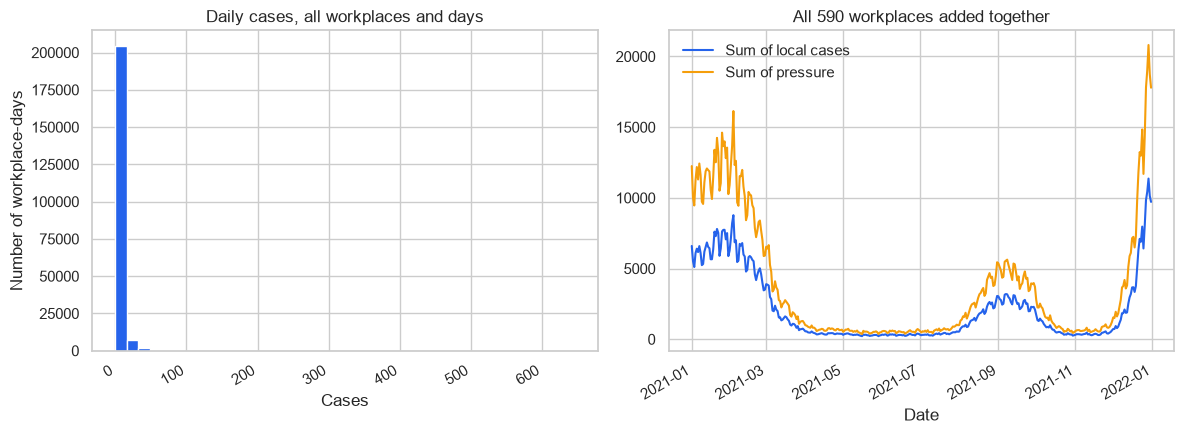

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].hist(panel.daily_cases, bins=40, color="#2563EB", edgecolor="white")
axes[0].set_title("Daily cases, all workplaces and days")
axes[0].set_xlabel("Cases")
axes[0].set_ylabel("Number of workplace-days")

statewide = panel.groupby("date")[["daily_cases", "pressure"]].sum()
axes[1].plot(statewide.index, statewide.daily_cases, color="#2563EB", label="Sum of local cases")
axes[1].plot(statewide.index, statewide.pressure, color="#F59E0B", label="Sum of pressure")
axes[1].set_title("All 590 workplaces added together")
axes[1].set_xlabel("Date")
axes[1].legend(frameon=False)
fig.autofmt_xdate(rotation=30)
fig.tight_layout()
plt.show()


## 7. Changes from yesterday

`velocity` is positive when cases rose and negative when they fell. The first three days of January are blank for `jerk`, so this chart starts on 4 January.


Rows with all three changes filled in: 213,580 of 215,350


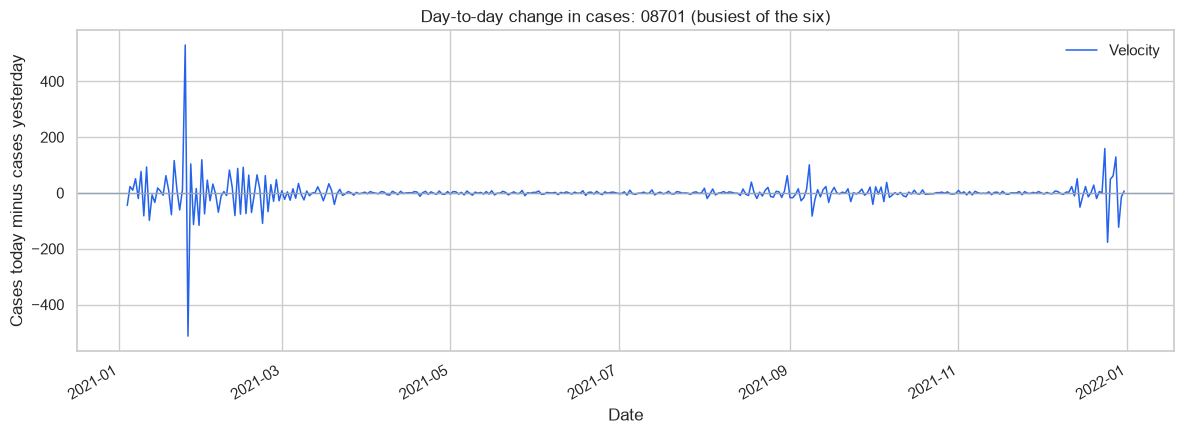

In [10]:
ready = panel.dropna(subset=["velocity", "acceleration", "jerk"])
print(f"Rows with all three changes filled in: {len(ready):,} of {len(panel):,}")

one = ready.loc[ready.zipcode.eq(picks.index[-1])]
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(one.date, one.velocity, color="#2563EB", linewidth=1.1, label="Velocity")
ax.axhline(0, color="#94A3B8", linewidth=1)
ax.set_title(f"Day-to-day change in cases: {picks.index[-1]} (busiest of the six)")
ax.set_ylabel("Cases today minus cases yesterday")
ax.set_xlabel("Date")
ax.legend(frameon=False)
fig.autofmt_xdate(rotation=30)
fig.tight_layout()
plt.show()
